# Vaccine Tweet Sentiment: Sequential Model Investigation

This notebook implements the group assignment around Zindi’s *To Vaccinate or Not to Vaccinate* challenge. It audits the supplied data, compares five distinct models, evaluates them on one fixed holdout set, and exports error examples. The two sparse baselines run with scikit-learn. BiLSTM, TextCNN, and XLM-R cells require PyTorch; XLM-R additionally requires Transformers and a cached/downloadable checkpoint.

**Important:** neural scores are only valid after executing their sections. Do not report unexecuted placeholder results. The notebook uses rounded sentiment classes for accuracy and macro-F1, and separate regression models for RMSE/MAE.

## Google Colab setup

Run this cell first in Colab. It installs dependencies, looks for the repository data, and prompts you to upload `Train.csv` and `Test.csv` if the files are not in the checkout. If you selected a GPU runtime, it also reports whether PyTorch can use it.


In [ ]:
%pip -q install pandas numpy scikit-learn matplotlib torch 'transformers[torch]' sentencepiece

from pathlib import Path
import os, subprocess, shutil
REPO_URL = 'https://github.com/Mahamatbt/NLP-and-Language-Technologies.git'
# Use CSVs already present in the current Colab folder; otherwise try the GitHub checkout.
if Path('data/Train.csv').exists() and Path('data/Test.csv').exists():
    PROJECT_DIR = Path.cwd()
else:
    PROJECT_DIR = Path('/content/NLP-and-Language-Technologies')
    if not (PROJECT_DIR / 'data' / 'Train.csv').exists():
        if PROJECT_DIR.exists(): shutil.rmtree(PROJECT_DIR)
        clone = subprocess.run(['git','clone',REPO_URL,str(PROJECT_DIR)],capture_output=True,text=True)
    if not (PROJECT_DIR / 'data' / 'Train.csv').exists():
        print('CSV files were not found in the current folder or GitHub checkout. Upload Train.csv and Test.csv when prompted.')
        from google.colab import files
        uploaded = files.upload()
        PROJECT_DIR = Path('/content')
        data_dir = PROJECT_DIR / 'data'; data_dir.mkdir(exist_ok=True)
        for filename, content in uploaded.items():
            if filename in {'Train.csv','Test.csv','SampleSubmission.csv'}:
                (data_dir / filename).write_bytes(content)
os.chdir(PROJECT_DIR)
assert Path('data/Train.csv').exists() and Path('data/Test.csv').exists(), 'Required files Train.csv and Test.csv are missing from data/. Rerun this setup cell and upload both files.'
import torch
print('Project folder:', Path.cwd())
print('Found CSVs:', sorted(p.name for p in Path('data').glob('*.csv')))
print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())

CSV files were not found in the current folder or GitHub checkout. Upload Train.csv and Test.csv when prompted.


Saving Test.csv to Test.csv
Saving Train.csv to Train.csv
Project folder: /content
Found CSVs: ['Test.csv', 'Train.csv']
PyTorch: 2.11.0+cu128 | CUDA available: True


In [ ]:
from pathlib import Path
import re, html, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import LinearSVC, LinearSVR
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, mean_squared_error,
                             mean_absolute_error, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA = Path('data'); OUT = Path('results'); OUT.mkdir(exist_ok=True)
train_raw = pd.read_csv(DATA/'Train.csv')
test = pd.read_csv(DATA/'Test.csv').fillna({'safe_text':''})
print('raw train', train_raw.shape, 'test', test.shape)
train_raw.head()

raw train (10001, 4) test (5177, 2)


,tweet_id,safe_text,label,agreement
0,CL1KWCMY,Me &amp; The Big Homie meanboy3000 #MEANBOY #M...,0.0,1.0
1,E3303EME,I'm 100% thinking of devoting my career to pro...,1.0,1.0
2,M4IVFSMS,"#whatcausesautism VACCINES, DO NOT VACCINATE Y...",-1.0,1.0
3,1DR6ROZ4,I mean if they immunize my kid with something ...,-1.0,1.0
4,J77ENIIE,Thanks to <user> Catch me performing at La Nui...,0.0,1.0


## Data audit and repair

The supplied CSV contains one empty-label record and one malformed row caused by a column shift. The latter has tweet text in `tweet_id`, `1` in `safe_text`, and a fractional value `2/3` in `label`. The repair below is narrowly rule-based and retains that continuous target. Every excluded/repaired record is printed for audit.

In [ ]:
bad = train_raw[~train_raw['label'].astype(str).str.fullmatch(r'-?\d+(?:\.\d+)?', na=False)]
print('Rows with nonnumeric/missing label:', len(bad)); display(bad)

def repair_row(row):
    text = row['safe_text']
    target = row['label']
    # Explicitly recognize the observed shifted record.
    if str(text).strip() in {'-1','0','1'} and str(row['tweet_id']).strip() not in {'-1','0','1'}:
        text = row['tweet_id']
    return pd.Series({'tweet_id': row['tweet_id'], 'safe_text': text, 'label': pd.to_numeric(target, errors='coerce'), 'agreement': pd.to_numeric(row.get('agreement'), errors='coerce')})

train = train_raw.apply(repair_row, axis=1).dropna(subset=['label']).reset_index(drop=True)
train['label'] = train['label'].astype(float)
train['class'] = train['label'].round().astype(int)
train['text'] = train['safe_text'].fillna('').astype(str)
assert len(train)==10000 and train['label'].between(-1,1).all()
print('usable rows:',len(train),'unique IDs:',train.tweet_id.nunique())
print('target distribution'); display(train['class'].value_counts().sort_index().rename_axis('sentiment').to_frame('count'))
print('fractional targets:',train.loc[train.label.ne(train['class']), ['tweet_id','text','label']])

Rows with nonnumeric/missing label: 1


,tweet_id,safe_text,label,agreement
4798,RQMQ0L2A,#lawandorderSVU,NaN,NaN


usable rows: 10000 unique IDs: 10000
target distribution


,count
sentiment,
-1,1038
0,4908
1,4054


fractional targets:                                                tweet_id  \
4798  I cannot believe in this day and age some pare...   

                                                   text     label  
4798  I cannot believe in this day and age some pare...  0.666667  


## Exploratory analysis

Counts and text-length summaries help set the sequence limit and reveal imbalance. Length here is whitespace-token count after minimal HTML entity decoding; original text is otherwise preserved for the models.

count    10000.000000
mean        16.268000
std          5.344664
min          1.000000
50%         17.000000
90%         23.000000
95%         24.000000
99%         27.000000
max         33.000000
Name: token_count, dtype: float64


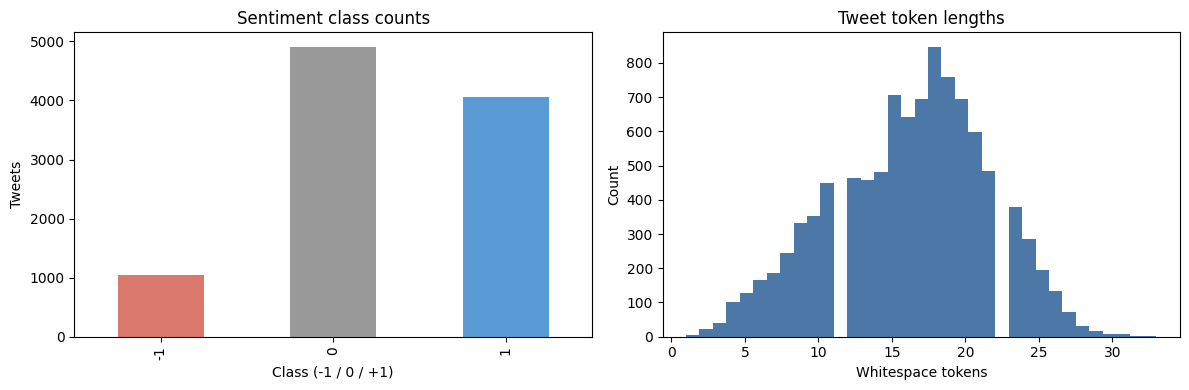

unique normalized word forms: 14125
frequent hashtags: {'#mmr': 373, '#measles': 341, '#vaccineswork': 146, '#vaccines': 122, '#vaccine': 98, '#ebola': 83, '#cdcwhistleblower': 74, '#autism': 73, '#vaccinate': 71, '#health': 57, '#vaccinations': 54, '#dc': 49, '#dj': 47, '#vaccinateyourkids': 46, '#gop': 44}
rows with URL/user placeholders: 0.6997


In [ ]:
train['tokens'] = train.text.map(lambda s: html.unescape(s).split())
train['token_count'] = train.tokens.map(len)
print(train.token_count.describe(percentiles=[.5,.9,.95,.99]))
fig, ax = plt.subplots(1,2,figsize=(12,4))
train['class'].value_counts().sort_index().plot.bar(ax=ax[0],color=['#d9796c','#999999','#5b9bd5'])
ax[0].set(title='Sentiment class counts',xlabel='Class (-1 / 0 / +1)',ylabel='Tweets')
ax[1].hist(train.token_count,bins=35,color='#4c78a8'); ax[1].set(title='Tweet token lengths',xlabel='Whitespace tokens',ylabel='Count')
fig.tight_layout(); fig.savefig(OUT/'eda.png',dpi=160); plt.show()
# Character-level vocabulary and common hashtag samples
all_text=' '.join(train.text).lower()
words=re.findall(r"[#@]?\w+",all_text)
print('unique normalized word forms:',len(set(words)))
print('frequent hashtags:',pd.Series([w for w in words if w.startswith('#')]).value_counts().head(15).to_dict())
print('rows with URL/user placeholders:',train.text.str.contains(r'<url>|<user>',case=False,regex=True).mean())

## Fixed validation split and metric helpers

The split is stratified by rounded sentiment class and fixed at seed 42. RMSE and MAE assess the original continuous target; accuracy and macro-F1 assess rounded classes. Confusion matrices and per-class reports make minority-class errors visible.

In [ ]:
tr_idx, va_idx = train_test_split(np.arange(len(train)),test_size=.20,random_state=SEED,stratify=train['class'])
X = train.text.to_numpy(); y = train.label.to_numpy(); yc = train['class'].to_numpy()
Xtr,Xva=X[tr_idx],X[va_idx]; ytr,yva=y[tr_idx],y[va_idx]; c_tr,c_va=yc[tr_idx],yc[va_idx]
LABELS=[-1,0,1]
results=[]; predictions={}
def score_model(name, pred_score, pred_class=None):
    pred_score=np.asarray(pred_score).reshape(-1)
    if pred_class is None: pred_class=np.clip(np.rint(pred_score),-1,1).astype(int)
    pred_class=np.asarray(pred_class).astype(int)
    row={'model':name,'accuracy':accuracy_score(c_va,pred_class),'macro_f1':f1_score(c_va,pred_class,average='macro')}
    results.append(row); predictions[name]=(pred_score,pred_class)
    print(row); print(classification_report(c_va,pred_class,labels=LABELS,zero_division=0,digits=3))
    ConfusionMatrixDisplay.from_predictions(c_va,pred_class,labels=LABELS,display_labels=LABELS,cmap='Blues')
    plt.title(name); plt.tight_layout(); plt.savefig(OUT/(re.sub(r'[^a-z0-9]+','_',name.lower()).strip('_')+'_cm.png'),dpi=150); plt.show()
    return row

## Model 1: TF-IDF + Logistic Regression

Word bigrams preserve short local phrases. Balanced class weights counter the underrepresented negative class. Decision scores provide a relative polarity score for regression metrics; they are monotonically mapped to [-1,1] for comparability.

{'model': 'TF-IDF + Logistic Regression', 'accuracy': 0.726, 'macro_f1': 0.671131601282922}
              precision    recall  f1-score   support

          -1      0.450     0.582     0.507       208
           0      0.820     0.759     0.788       981
           1      0.713     0.723     0.718       811

    accuracy                          0.726      2000
   macro avg      0.661     0.688     0.671      2000
weighted avg      0.738     0.726     0.730      2000



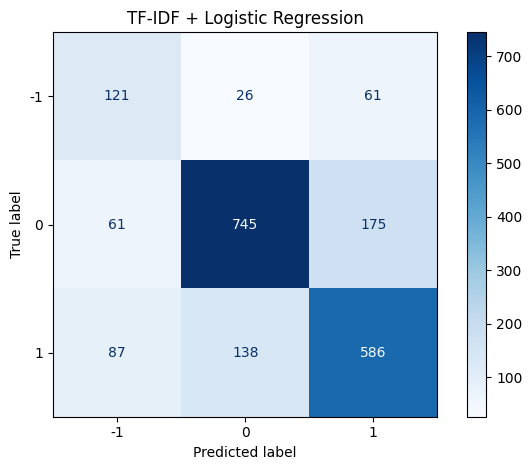

{'model': 'TF-IDF + Logistic Regression',
 'accuracy': 0.726,
 'macro_f1': 0.671131601282922}

In [ ]:
lr = Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=200000,sublinear_tf=True)),
               ('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED))])
lr.fit(Xtr,c_tr); lr_pred=lr.predict(Xva)
score_model('TF-IDF + Logistic Regression',lr_pred,lr_pred)

## Model 2: TF-IDF + Linear SVM

Linear SVM is a different optimization objective and is a strong high-dimensional sparse-text baseline. Its margin scores are scaled to [-1,1] for the auxiliary regression metrics; classification metrics use the model’s predicted class.

{'model': 'TF-IDF + Linear SVM', 'accuracy': 0.7335, 'macro_f1': 0.6656152731677837}
              precision    recall  f1-score   support

          -1      0.535     0.438     0.481       208
           0      0.800     0.778     0.789       981
           1      0.700     0.756     0.727       811

    accuracy                          0.734      2000
   macro avg      0.678     0.657     0.666      2000
weighted avg      0.732     0.734     0.732      2000



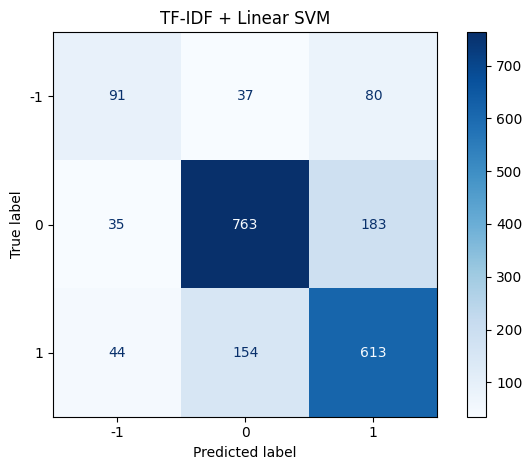

{'model': 'TF-IDF + Linear SVM',
 'accuracy': 0.7335,
 'macro_f1': 0.6656152731677837}

In [ ]:
svm = Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=200000,sublinear_tf=True)),
                ('model',LinearSVC(class_weight='balanced',random_state=SEED))])
svm.fit(Xtr,c_tr); svm_pred=svm.predict(Xva)
score_model('TF-IDF + Linear SVM',svm_pred,svm_pred)

## Neural models (optional dependencies)

The next section defines three sequence architectures with a shared vocabulary/tokenization setup. Install PyTorch before running. Training defaults are deliberately modest; tune against the fixed validation split only and record any changes. The XLM-R model requires `transformers` and a pretrained checkpoint available in the runtime.

In [ ]:
try:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    TORCH_AVAILABLE=True
    DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
    print('PyTorch',torch.__version__,'device',DEVICE)
except ImportError:
    TORCH_AVAILABLE=False
    print('PyTorch unavailable: neural model cells are not run; no neural results should be reported.')

PyTorch 2.11.0+cu128 device cuda


In [ ]:
# Simple word tokenizer and vocabulary for BiLSTM and TextCNN
from collections import Counter
TOKEN_RE=re.compile(r"<[^>]+>|[#@]?\w+|[^\w\s]",re.UNICODE)
def tokenize(s): return TOKEN_RE.findall(html.unescape(str(s)).lower())
train_tok=[tokenize(s) for s in Xtr]; val_tok=[tokenize(s) for s in Xva]
vocab={'<pad>':0,'<unk>':1}
for tok,n in Counter(t for row in train_tok for t in row).items():
    if n>=2: vocab[tok]=len(vocab)
MAX_LEN=64

def encode(tokens):
    ids=[vocab.get(t,1) for t in tokens[:MAX_LEN]]
    return ids+[0]*(MAX_LEN-len(ids))
Xtr_ids=np.array([encode(t) for t in train_tok]); Xva_ids=np.array([encode(t) for t in val_tok])
print('vocab',len(vocab),'truncated validation fraction',np.mean([len(t)>MAX_LEN for t in val_tok]))

vocab 5670 truncated validation fraction 0.0


In [ ]:
if TORCH_AVAILABLE:
    class TweetDataset(Dataset):
        def __init__(self,ids,labels): self.ids=torch.tensor(ids,dtype=torch.long); self.labels=torch.tensor(labels,dtype=torch.float32)
        def __len__(self): return len(self.labels)
        def __getitem__(self,i): return self.ids[i],self.labels[i]
    tr_loader=DataLoader(TweetDataset(Xtr_ids,ytr),batch_size=64,shuffle=True)
    va_loader=DataLoader(TweetDataset(Xva_ids,yva),batch_size=128)

    class BiLSTMRegressor(nn.Module):
        def __init__(self,vsize,emb=128,hid=96):
            super().__init__(); self.emb=nn.Embedding(vsize,emb,padding_idx=0); self.rnn=nn.LSTM(emb,hid,batch_first=True,bidirectional=True)
            self.drop=nn.Dropout(.35); self.fc=nn.Linear(hid*2,1)
        def forward(self,x):
            z=self.emb(x); out,_=self.rnn(z); mask=(x!=0).unsqueeze(-1); pooled=(out*mask).sum(1)/mask.sum(1).clamp(min=1)
            return torch.tanh(self.fc(self.drop(pooled))).squeeze(-1)

    class TextCNNRegressor(nn.Module):
        def __init__(self,vsize,emb=128,channels=96):
            super().__init__(); self.emb=nn.Embedding(vsize,emb,padding_idx=0)
            self.convs=nn.ModuleList([nn.Conv1d(emb,channels,k) for k in (2,3,4)])
            self.drop=nn.Dropout(.4); self.fc=nn.Linear(channels*3,1)
        def forward(self,x):
            z=self.emb(x).transpose(1,2)
            pooled=[torch.relu(conv(z)).amax(dim=2) for conv in self.convs]
            return torch.tanh(self.fc(self.drop(torch.cat(pooled,dim=1)))).squeeze(-1)

    def fit_torch(model,epochs=8,lr=1e-3):
        model=model.to(DEVICE); opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4); loss_fn=nn.MSELoss()
        history={'train':[],'val':[]}; best=float('inf'); best_state=None
        for ep in range(epochs):
            model.train(); losses=[]
            for bx,by in tr_loader:
                bx,by=bx.to(DEVICE),by.to(DEVICE); opt.zero_grad(); loss=loss_fn(model(bx),by); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); losses.append(loss.item())
            model.eval(); vpred=[]; vtrue=[]
            with torch.no_grad():
                for bx,by in va_loader:
                    vpred.extend(model(bx.to(DEVICE)).cpu().numpy()); vtrue.extend(by.numpy())
            val_loss=mean_squared_error(vtrue,vpred); history['train'].append(float(np.mean(losses))); history['val'].append(float(val_loss))
            if val_loss<best: best=val_loss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            print(f'epoch {ep+1}: train_mse={history["train"][-1]:.4f} val_rmse={val_loss**.5:.4f}')
        model.load_state_dict(best_state); model.eval()
        with torch.no_grad(): pred=model(torch.tensor(Xva_ids,dtype=torch.long,device=DEVICE)).cpu().numpy()
        return model,history,pred
else:
    print('Skipping BiLSTM/TextCNN definitions that depend on PyTorch.')

### Model 3: BiLSTM

Run this cell if PyTorch is installed. The bidirectional recurrent layer reads each tweet in both directions and regresses the sentiment score. The best validation-MSE epoch is restored.

epoch 1: train_mse=0.3813 val_rmse=0.5930
epoch 2: train_mse=0.3372 val_rmse=0.5829
epoch 3: train_mse=0.2940 val_rmse=0.5742
epoch 4: train_mse=0.2457 val_rmse=0.5729
epoch 5: train_mse=0.1959 val_rmse=0.5883
epoch 6: train_mse=0.1474 val_rmse=0.6079
epoch 7: train_mse=0.1102 val_rmse=0.6040
epoch 8: train_mse=0.0849 val_rmse=0.6063
{'model': 'BiLSTM', 'accuracy': 0.6625, 'macro_f1': 0.48918509750650796}
              precision    recall  f1-score   support

          -1      1.000     0.053     0.100       208
           0      0.624     0.879     0.730       981
           1      0.745     0.557     0.638       811

    accuracy                          0.662      2000
   macro avg      0.789     0.496     0.489      2000
weighted avg      0.712     0.662     0.627      2000



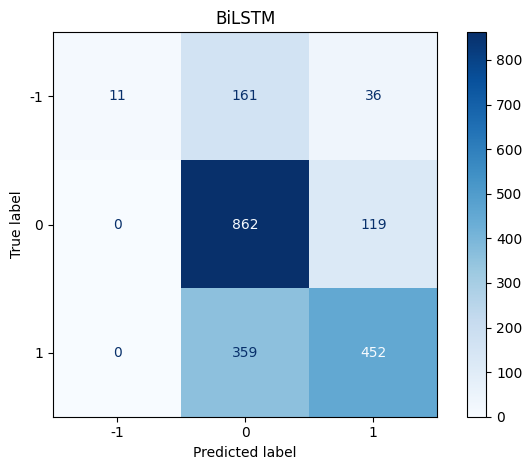

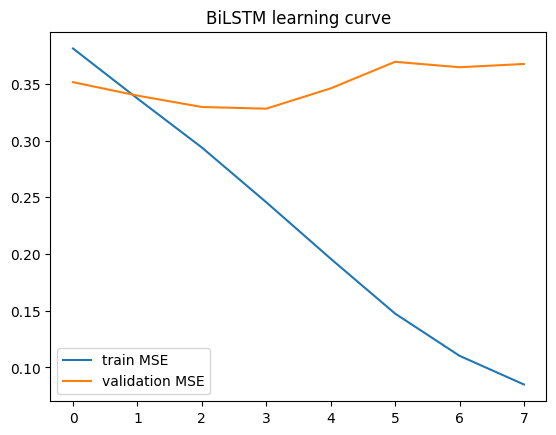

In [ ]:
if TORCH_AVAILABLE:
    bilstm, hist_lstm, pred_lstm=fit_torch(BiLSTMRegressor(len(vocab)))
    score_model('BiLSTM',pred_lstm)
    plt.plot(hist_lstm['train'],label='train MSE'); plt.plot(hist_lstm['val'],label='validation MSE'); plt.legend(); plt.title('BiLSTM learning curve'); plt.savefig(OUT/'bilstm_learning_curve.png',dpi=150); plt.show()

### Model 4: TextCNN

Convolution widths 2, 3, and 4 detect local sentiment phrases; global max pooling selects salient features. This model has no recurrent state and provides a distinct neural comparison.

epoch 1: train_mse=0.4685 val_rmse=0.5830
epoch 2: train_mse=0.3435 val_rmse=0.5840
epoch 3: train_mse=0.3055 val_rmse=0.5898
epoch 4: train_mse=0.2674 val_rmse=0.5671
epoch 5: train_mse=0.2493 val_rmse=0.5672
epoch 6: train_mse=0.2249 val_rmse=0.5781
epoch 7: train_mse=0.1971 val_rmse=0.5716
epoch 8: train_mse=0.1890 val_rmse=0.5716
{'model': 'TextCNN', 'accuracy': 0.6755, 'macro_f1': 0.4978384980981066}
              precision    recall  f1-score   support

          -1      0.909     0.048     0.091       208
           0      0.634     0.877     0.736       981
           1      0.760     0.593     0.666       811

    accuracy                          0.675      2000
   macro avg      0.768     0.506     0.498      2000
weighted avg      0.714     0.675     0.641      2000



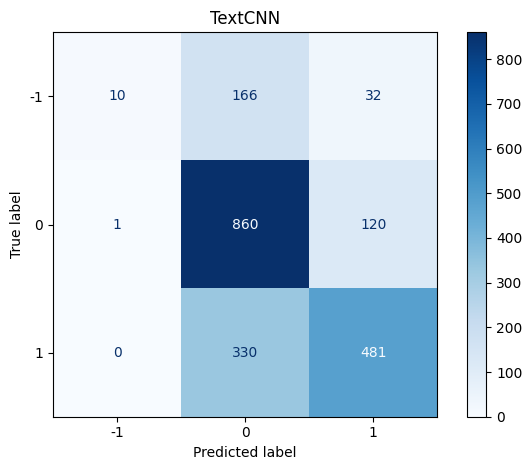

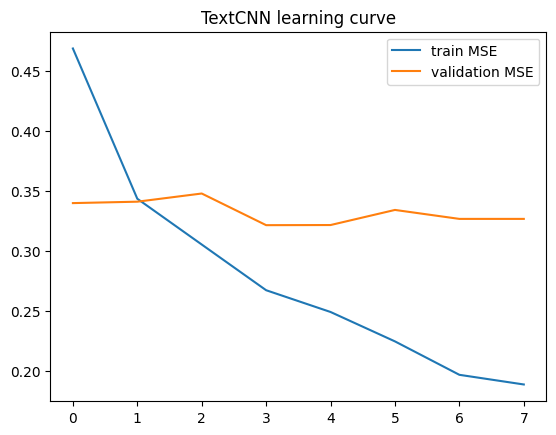

In [ ]:
if TORCH_AVAILABLE:
    textcnn, hist_cnn, pred_cnn=fit_torch(TextCNNRegressor(len(vocab)))
    score_model('TextCNN',pred_cnn)
    plt.plot(hist_cnn['train'],label='train MSE'); plt.plot(hist_cnn['val'],label='validation MSE'); plt.legend(); plt.title('TextCNN learning curve'); plt.savefig(OUT/'textcnn_learning_curve.png',dpi=150); plt.show()

### Model 5: Fine-tuned XLM-R

This Hugging Face model uses subword tokenization and multilingual contextual pretraining. It may require network access the first time the checkpoint is loaded. Use best validation RMSE for checkpoint selection. If unavailable, report the limitation rather than substituting a fabricated result.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,0.377294,0.322052
2,0.294907,0.291169
3,0.227090,0.288398


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'model': 'XLM-R', 'accuracy': 0.7465, 'macro_f1': 0.6117667392004901}
              precision    recall  f1-score   support

          -1      0.750     0.173     0.281       208
           0      0.731     0.851     0.787       981
           1      0.768     0.767     0.767       811

    accuracy                          0.747      2000
   macro avg      0.750     0.597     0.612      2000
weighted avg      0.748     0.747     0.726      2000



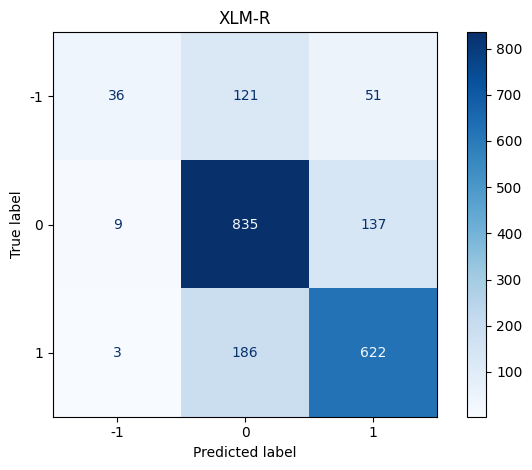

In [ ]:
# Optional: pip install transformers (and ensure checkpoint access)
try:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
    TRANSFORMERS_AVAILABLE=True
except ImportError:
    TRANSFORMERS_AVAILABLE=False
    print('Transformers unavailable; XLM-R not run.')

try:
    import torch
    from torch.utils.data import Dataset
    TORCH_AVAILABLE=True
except ImportError:
    TORCH_AVAILABLE=False

from pathlib import Path
if 'OUT' not in globals():
    OUT = Path('results')
    OUT.mkdir(exist_ok=True)

if 'SEED' not in globals():
    SEED = 42

# Check if the split variables exist before executing
if 'Xtr' not in globals() or 'ytr' not in globals() or 'Xva' not in globals() or 'yva' not in globals():
    raise NameError("Data split variables (Xtr, ytr, Xva, yva) are missing. Please execute the fixed validation split cell (4lj1TsVPUyaM) before running this cell.")

if TRANSFORMERS_AVAILABLE and TORCH_AVAILABLE:
    CHECKPOINT='xlm-roberta-base'
    tokenizer=AutoTokenizer.from_pretrained(CHECKPOINT)
    class HFDataset(Dataset):
        def __init__(self,texts,labels):
            self.enc=tokenizer(list(texts),truncation=True,padding='max_length',max_length=96)
            self.labels=np.asarray(labels,dtype=np.float32)
        def __len__(self): return len(self.labels)
        def __getitem__(self,i):
            out={k:torch.tensor(v[i]) for k,v in self.enc.items()}; out['labels']=torch.tensor(self.labels[i]); return out
    hf_model=AutoModelForSequenceClassification.from_pretrained(CHECKPOINT,num_labels=1,problem_type='regression')
    # Correct problem_type spelling for HF model configs:
    hf_model.config.problem_type='regression'
    args=TrainingArguments(output_dir=str(OUT/'xlmr_checkpoints'),num_train_epochs=3,learning_rate=2e-5,
        per_device_train_batch_size=16,per_device_eval_batch_size=32,weight_decay=.01,
        eval_strategy='epoch',save_strategy='epoch',load_best_model_at_end=True,
        metric_for_best_model='eval_loss',greater_is_better=False,seed=SEED,logging_strategy='epoch',report_to=[])
    trainer=Trainer(model=hf_model,args=args,train_dataset=HFDataset(Xtr,ytr),eval_dataset=HFDataset(Xva,yva))
    trainer.train(); pred_xl=trainer.predict(HFDataset(Xva,yva)).predictions.reshape(-1)
    score_model('XLM-R',pred_xl)
    pd.DataFrame(trainer.state.log_history).to_csv(OUT/'xlmr_training_log.csv',index=False)

## Model comparison and error analysis

The table is populated with models actually run. Inspect the saved confusion matrices and top errors. When reading examples, distinguish model failure from plausible label ambiguity; anonymized placeholders in the source should remain anonymized.

,model,accuracy,macro_f1
0,TF-IDF + Logistic Regression,0.7260,0.671132
1,TF-IDF + Linear SVM,0.7335,0.665615
4,XLM-R,0.7465,0.611767
3,TextCNN,0.6755,0.497838
2,BiLSTM,0.6625,0.489185



 BiLSTM largest score errors


,gold_class,pred_class,gold_score,pred_score,text,abs_error
4196,-1,1,-1.0,0.988958,<user> herd immunity is protecting those who d...,1.988958
5291,-1,1,-1.0,0.943932,<user> Happy to find you on Twitter. My childr...,1.943932
5299,-1,1,-1.0,0.941721,"In 1985,14 students in Corpus Christi, Tx. con...",1.941721
4252,-1,1,-1.0,0.931576,<user> <user> but but vaccinations cause autis...,1.931576
5799,-1,1,-1.0,0.929235,"As anti-vaccine communities grow, measles and ...",1.929235
5075,-1,1,-1.0,0.911917,Let's be honest Diseases are here to wipe out ...,1.911917
5338,-1,1,-1.0,0.891469,"<user> show me proof that giving 4,5,6,7+ vacc...",1.891469
5487,-1,1,-1.0,0.858913,<user> darn colds! One of my coworkers got Gui...,1.858913
5315,-1,1,-1.0,0.856048,I don't want kids cause I'm gonna give my kids...,1.856048
5413,-1,1,-1.0,0.822964,Thr ARE some babies/children who CANNOT get #v...,1.822964



 TF-IDF + Linear SVM largest score errors


,gold_class,pred_class,gold_score,pred_score,text,abs_error
2014,-1,1,-1.0,1.0,<user> <user> thank you! I had Lyme disease wa...,2.0
2025,-1,1,-1.0,1.0,<user> I AM against the poisons they want to i...,2.0
2026,-1,1,-1.0,1.0,<user> Wow No Fax just fear so no vaccination ...,2.0
2031,1,-1,1.0,-1.0,“<user> How Can it be About the Money? #Immuni...,2.0
2057,-1,1,-1.0,1.0,historical &amp; scientific critique of the th...,2.0
2080,-1,1,-1.0,1.0,Inconvenient truth behind vaccinations and aut...,2.0
2087,-1,1,-1.0,1.0,More parents opting out of vaccinating childre...,2.0
2089,1,-1,1.0,-1.0,<user> All diseases that are scarce due vaccin...,2.0
2116,1,-1,1.0,-1.0,.<user> is leading &amp; participating in the ...,2.0
2127,1,-1,1.0,-1.0,“<user> Scientists Implicate More Than 100 Gen...,2.0


...

,gold_class,pred_class,gold_score,pred_score,text,abs_error
7799,-1,1,-1.0,0.879257,"As anti-vaccine communities grow, measles and ...",1.879257
6287,-1,1,-1.0,0.865699,"speechless, met people that are proud for not ...",1.865699
7260,-1,1,-1.0,0.828631,<user> while I respect your decision to vaccin...,1.828631
7745,-1,1,-1.0,0.785879,"“<user> Moms and dads, did you vaccinate your ...",1.785879
6252,-1,1,-1.0,0.784354,<user> <user> but but vaccinations cause autis...,1.784354
6787,-1,1,-1.0,0.773684,"IDIOT ""<user> Kristin Cavallari defends her an...",1.773684
6196,-1,1,-1.0,0.706061,<user> herd immunity is protecting those who d...,1.706061
6169,-1,1,-1.0,0.703412,"In a 2012 #measles outbreak in Quebec, Canada,...",1.703412
6626,-1,1,-1.0,0.686464,<user> vaccinating your children to protect th...,1.686464
7778,-1,1,-1.0,0.675878,Anti-vaxxers now have a children's book extoll...,1.675878



 XLM-R largest score errors


,gold_class,pred_class,gold_score,pred_score,text,abs_error
8169,-1,1,-1.0,1.089832,"In a 2012 #measles outbreak in Quebec, Canada,...",2.089832
8196,-1,1,-1.0,1.072290,<user> herd immunity is protecting those who d...,2.072290
9778,-1,1,-1.0,1.066575,Anti-vaxxers now have a children's book extoll...,2.066575
9799,-1,1,-1.0,1.066541,"As anti-vaccine communities grow, measles and ...",2.066541
8837,-1,1,-1.0,1.060706,Heads up if you haven't got your measles vaccine,2.060706
9338,-1,1,-1.0,1.030189,"<user> show me proof that giving 4,5,6,7+ vacc...",2.030189
8057,-1,1,-1.0,1.017616,historical &amp; scientific critique of the th...,2.017616
8287,-1,1,-1.0,1.005092,"speechless, met people that are proud for not ...",2.005092
9495,-1,1,-1.0,0.954330,"Finally, the truth is coming out. This vaccine...",1.954330
8757,-1,1,-1.0,0.933686,Sure vaccines may prevent disease but what abo...,1.933686


,model,RMSE,MAE
0,TF-IDF + Ridge (diagnostic),0.561344,0.425677
1,TF-IDF + LinearSVR (diagnostic),0.575910,0.406943


Five required approaches are TF-IDF Logistic Regression, TF-IDF Linear SVM, BiLSTM, TextCNN, and XLM-R. Ridge/LinearSVR are extra continuous-score diagnostics, not part of that five-model set.


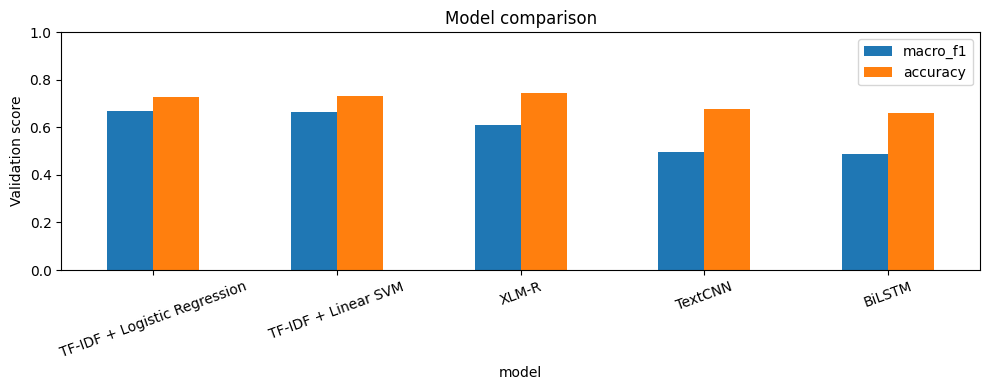

In [ ]:
comparison=pd.DataFrame(results).sort_values('macro_f1',ascending=False)
display(comparison)
comparison.to_csv(OUT/'model_comparison.csv',index=False)

# Persist validation predictions and inspect errors for each completed model.
err_frames=[]
for name,(ps,pc) in predictions.items():
    df=pd.DataFrame({'model':name,'tweet_id':train.iloc[va_idx].tweet_id.values,'text':Xva,
                     'gold_score':yva,'gold_class':c_va,'pred_score':ps,'pred_class':pc})
    df['abs_error']=(df.gold_score-df.pred_score).abs(); df['wrong_class']=df.gold_class.ne(df.pred_class)
    df['agreement']=train.iloc[va_idx].agreement.to_numpy()
    df['token_count']=pd.Series(Xva).str.split().str.len().to_numpy()
    df['has_hashtag']=pd.Series(Xva).str.contains('#',regex=False).to_numpy()
    df['has_placeholder']=pd.Series(Xva).str.contains(r'<url>|<user>',case=False,regex=True).to_numpy()
    err_frames.append(df)
errors=pd.concat(err_frames,ignore_index=True)
errors.to_csv(OUT/'validation_predictions_and_errors.csv',index=False)
for name,g in errors[errors.wrong_class].groupby('model'):
    print('\n',name,'largest score errors')
    display(g.nlargest(10,'abs_error')[['gold_class','pred_class','gold_score','pred_score','text','abs_error']])

# Separate continuous-score diagnostics (not counted among the five assigned approaches).
ridge=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=200000,sublinear_tf=True)),('model',Ridge(alpha=1.0))])
ridge.fit(Xtr,ytr); ridge_p=ridge.predict(Xva)
svr=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=200000,sublinear_tf=True)),('model',LinearSVR(C=.5,random_state=SEED,max_iter=5000))])
svr.fit(Xtr,ytr); svr_p=svr.predict(Xva)
regression_diagnostics=pd.DataFrame([{'model':'TF-IDF + Ridge (diagnostic)','RMSE':mean_squared_error(yva,ridge_p)**.5,'MAE':mean_absolute_error(yva,ridge_p)}, {'model':'TF-IDF + LinearSVR (diagnostic)','RMSE':mean_squared_error(yva,svr_p)**.5,'MAE':mean_absolute_error(yva,svr_p)}])
display(regression_diagnostics); regression_diagnostics.to_csv(OUT/'regression_diagnostics.csv',index=False)
print('Five required approaches are TF-IDF Logistic Regression, TF-IDF Linear SVM, BiLSTM, TextCNN, and XLM-R. Ridge/LinearSVR are extra continuous-score diagnostics, not part of that five-model set.')

# Visual comparison
if len(comparison):
    ax=comparison.set_index('model')[['macro_f1','accuracy']].plot.bar(figsize=(10,4),ylim=(0,1),rot=20)
    ax.set_ylabel('Validation score'); ax.set_title('Model comparison'); plt.tight_layout(); plt.savefig(OUT/'model_comparison.png',dpi=160); plt.show()

## Interpretation checklist

- Compare RMSE/MAE as continuous competition metrics, and macro-F1 as the imbalance-aware class metric.
- Check per-class recall, especially negative sentiment.
- Use confusion matrices to identify polarity/neutral confusions.
- Inspect the exported examples before attributing errors to sarcasm, negation, rare vocabulary, or annotation disagreement.
- Include model runtime and tuning notes in the report after neural experiments complete.
- The starter notebook’s reported leaderboard results are external examples and must not be presented as this group’s validation results.